# 4. házi — Saját bináris klasszifikátor: pénzügyi nehézség előrejelzése

**Adat:** Kaggle „Give Me Some Credit” (2011-es verseny; OpenML `data_id=46929`): 150 000 hitelfelvevő, 10 magyarázó változó.
**Célváltozó:** `FinancialDistressNextTwoYears`: az ügyfél a következő két évben legalább 90 napos késedelembe esik (Yes = 1).

Minden szám ebből a notebookból jön, rögzített seedekkel. Az ábrák az `abrak/` mappába is kimentődnek.

## 1. A kérdés és a célváltozó

**Kérdés:** a hitelkérelem idején ismert adatokból (életkor, jövedelem, eladósodottság, korábbi késések) előre jelezhető-e, hogy az ügyfél két éven belül súlyos (90+ napos) késedelembe esik?

**Pozitív (1):** súlyos késedelem két éven belül. **Negatív (0):** nincs ilyen.

**Mibe kerül a tévedés?**
- **Kihagyott pozitív (FN):** hitelt adunk valakinek, aki nem fizet vissza. A bank elveszítheti a tőke jelentős részét, ehhez jön a behajtás költsége.
- **Álriasztás (FP):** egy jó ügyfelet elutasítunk vagy kézi átvilágításra küldünk. Ennek ára az elmaradt kamatbevétel és az ügyintéző ideje.
- Egy FN nagyságrendekkel drágább, mint egy FP (durva feltevés: 5–10×), ezért a recall fontosabb a precisionnél. Mindenkit elutasítani viszont nem lehet.

**Döntési szabály (előre rögzítve, mielőtt bármilyen eredményt láttam):** a bank a kérelmek **10%-át** tudja kézzel átvilágítani. A modell feladata ezért a *rangsorolás*: jelölje meg a legkockázatosabb 10%-ot. A küszöb a tanító halmaz out-of-fold pontszámainak 90. percentilise.

**Mutatók (előre rögzítve):** a fő mutató a **PR-AUC** (átlagos precision). Mellette: kiegyensúlyozott pontosság, konfúziós mátrix, és a legkockázatosabb 10% **találati aránya** (a megjelöltek közül hány valódi pozitív) és **lefedése** (a pozitívak hányadát fogjuk meg).

**Miért nem a nyers pontosság?** A pozitívak aránya ~6,7%. A „senki sem kerül bajba” modell így ~93%-ban eltalálja a választ, de egyetlen kockázatos ügyfelet sem talál meg. A pontosság ráadásul *bünteti* a hasznos, alacsony küszöböt: egy ritka osztálynál minden további megjelölt ügyfél több FP-t hoz, mint TP-t, így a pontosság csökken, miközben a recall nő (a 6. fejezet táblázata ezt számokkal is megmutatja).

In [1]:
import time, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.datasets import fetch_openml
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             average_precision_score, roc_auc_score, confusion_matrix, precision_recall_curve)
from xgboost import XGBClassifier
from scipy.stats import randint, uniform, loguniform

SEED = 42
FIG = Path("abrak"); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, GRAY = "#2f66a8", "#d0612a", "#888888"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 10})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150); plt.show()
T0 = time.time(); tick = lambda msg: print(f"[{time.time() - T0:5.0f} s] {msg}")
pd.set_option("display.width", 200, "display.max_columns", 30)

## 2. A split előbb: zárolt teszthalmaz

A betöltés után **azonnal** leválasztom a teszthalmazt. Az EDA, a tisztítási döntések és minden modellválasztás már csak a tanító halmazon történik, így a tesztadat még közvetve sem szivároghat be egyetlen döntésbe sem. (Az órai demo az EDA-t a teljes adaton végezte; itt szigorúbb vagyok.)

- **80/20** arány, **rétegzés** a célváltozó szerint: a ritka pozitív osztály aránya mindkét részben ugyanannyi lesz. `random_state=42`.
- Az adat **nem időbeli**: nincs dátumoszlop, és a Kaggle-verseny is véletlen vágást használt. A véletlen vágás ezért itt helyes.
- **Ugyanazok a foldok mindenkinek:** `StratifiedKFold(5, shuffle=True, random_state=42)`. A páros összehasonlításokhoz egy rögzített 5×2-es ismételt változatot használok, így több fold jut egy-egy különbség becslésére.

In [2]:
NAMES = {"FinancialDistressNextTwoYears": "target", "RevolvingUtilizationOfUnsecuredLines": "util", "age": "age",
         "NumberOfTime30-59DaysPastDueNotWorse": "late30", "DebtRatio": "debt_ratio", "MonthlyIncome": "income",
         "NumberOfOpenCreditLinesAndLoans": "open_lines", "NumberOfTimes90DaysLate": "late90",
         "NumberRealEstateLoansOrLines": "re_loans", "NumberOfTime60-89DaysPastDueNotWorse": "late60",
         "NumberOfDependents": "dependents"}
raw = fetch_openml(data_id=46929, as_frame=True).frame.rename(columns=NAMES)
y_all = (raw.pop("target") == "Yes").astype(int)
print(raw.shape, f"| pozitív arány a teljes adaton: {y_all.mean():.2%}")

X_train_raw, X_test_raw, y_train, y_test = train_test_split(raw, y_all, test_size=.2, stratify=y_all, random_state=SEED)
X_train_raw, X_test_raw = X_train_raw.reset_index(drop=True), X_test_raw.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)
# ---- X_test_raw / y_test ZÁROLVA a 9. fejezetig. Addig minden a tanító halmazon, keresztvalidációval. ----
print(f"train: {len(X_train_raw):,} sor, pozitív {y_train.mean():.2%} ({y_train.sum():,} db) | "
      f"teszt: {len(X_test_raw):,} sor, pozitív {y_test.mean():.2%}")

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

(150000, 10) | pozitív arány a teljes adaton: 6.68%
train: 120,000 sor, pozitív 6.68% (8,021 db) | teszt: 30,000 sor, pozitív 6.68%


**A változók** (rövid nevekre átnevezve):

| rövid név | eredeti | jelentés |
|---|---|---|
| `util` | RevolvingUtilizationOfUnsecuredLines | a rulírozó (fedezetlen) hitelkeretek kihasználtsága: egyenleg / keret |
| `age` | age | életkor (év) |
| `late30`, `late60`, `late90` | NumberOfTime30-59… / 60-89… / 90DaysLate | hányszor késett 30–59, 60–89, illetve 90+ napot (az elmúlt két évben) |
| `debt_ratio` | DebtRatio | havi adósságtörlesztés, lakhatás stb. / havi bruttó jövedelem |
| `income` | MonthlyIncome | havi jövedelem |
| `open_lines` | NumberOfOpenCreditLinesAndLoans | nyitott hitelek és hitelkártyák száma |
| `re_loans` | NumberRealEstateLoansOrLines | ingatlanhitelek száma |
| `dependents` | NumberOfDependents | eltartottak száma |

## 3. EDA (csak a tanító halmazon)

In [3]:
print(f"célváltozó: {y_train.mean():.2%} pozitív  ->  a konstans 'nincs baj' modell pontossága {1 - y_train.mean():.2%}")
display(X_train_raw.describe().T.round(3))

célváltozó: 6.68% pozitív  ->  a konstans 'nincs baj' modell pontossága 93.32%


,count,mean,std,min,25%,50%,75%,max
util,120000.0,5.808,221.340,0.0,0.030,0.155,0.561,29110.0
age,120000.0,52.285,14.760,0.0,41.000,52.000,63.000,109.0
late30,120000.0,0.428,4.275,0.0,0.000,0.000,0.000,98.0
debt_ratio,120000.0,354.509,1991.892,0.0,0.176,0.367,0.872,326442.0
income,96168.0,6701.567,15737.055,0.0,3400.000,5400.000,8250.000,3008750.0
open_lines,120000.0,8.459,5.157,0.0,5.000,8.000,11.000,58.0
late90,120000.0,0.272,4.252,0.0,0.000,0.000,0.000,98.0
re_loans,120000.0,1.020,1.127,0.0,0.000,1.000,2.000,54.0
late60,120000.0,0.246,4.238,0.0,0.000,0.000,0.000,98.0
dependents,116817.0,0.756,1.114,0.0,0.000,0.000,1.000,20.0


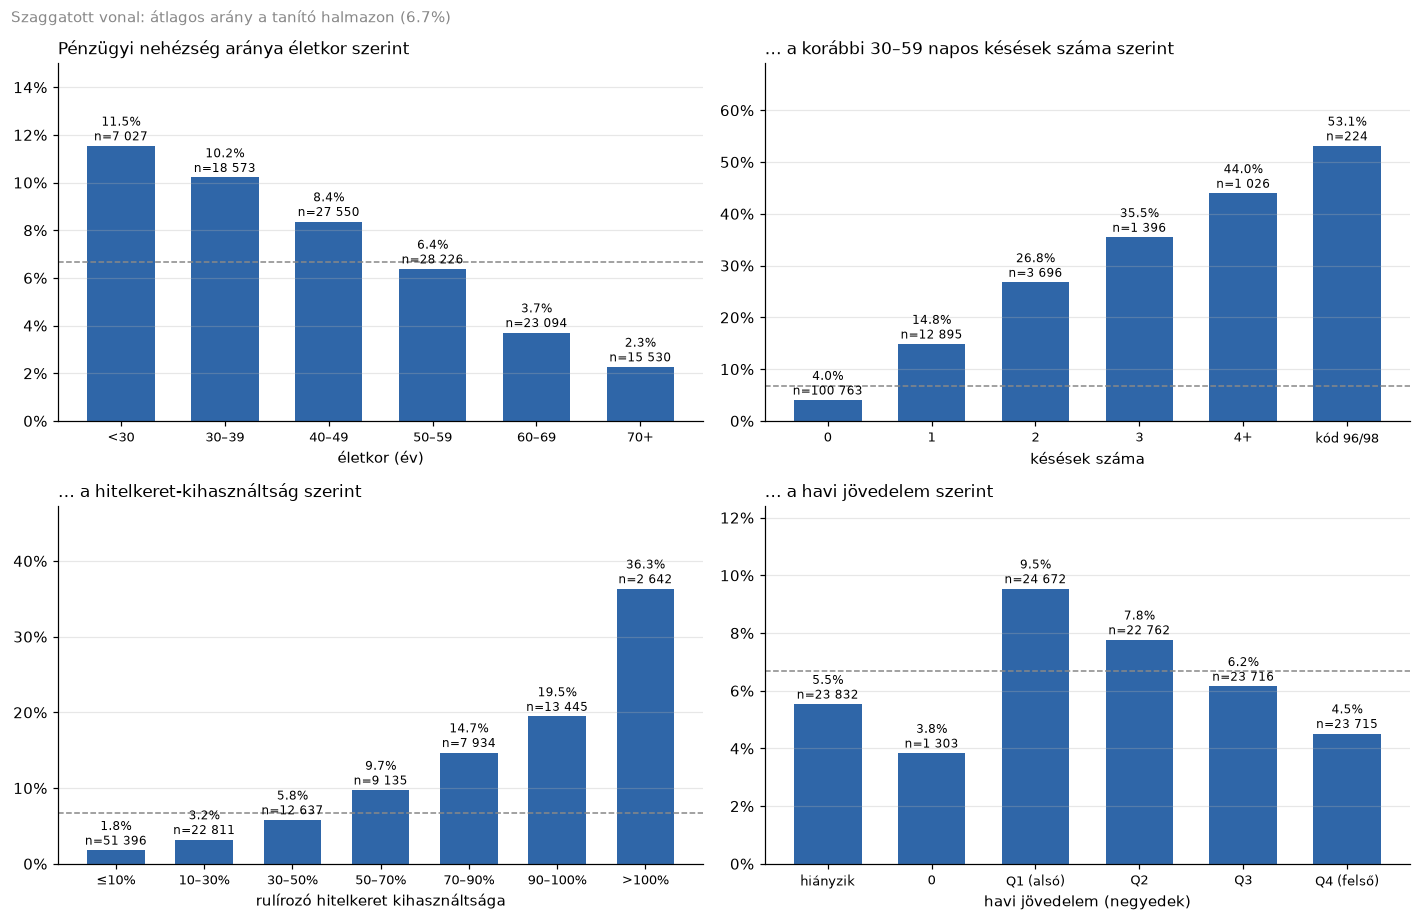

In [4]:
d = X_train_raw.assign(y=y_train.values); base = y_train.mean()
def rate_bar(ax, groups, title, xlabel):
    r = d.groupby(groups, observed=True).y.agg(["mean", "size"])
    ax.bar(range(len(r)), r["mean"], color=BLUE, width=.65)
    for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
        ax.text(i, m + r["mean"].max() * .02, f"{m:.1%}\nn={n:,}".replace(",", " "), ha="center", fontsize=8)
    ax.axhline(base, ls="--", color=GRAY, lw=1)
    ax.set_xticks(range(len(r))); ax.set_xticklabels([str(i) for i in r.index], fontsize=8.5)
    ax.set_title(title, loc="left", fontsize=11); ax.set_xlabel(xlabel); ax.set_ylim(0, r["mean"].max() * 1.3)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.grid(axis="x", visible=False)

fig, axs = plt.subplots(2, 2, figsize=(13, 8.5))
rate_bar(axs[0, 0], pd.cut(d.age, [0, 30, 40, 50, 60, 70, 200], right=False, labels=["<30", "30–39", "40–49", "50–59", "60–69", "70+"]),
         "Pénzügyi nehézség aránya életkor szerint", "életkor (év)")
late = d.late30.where(d.late30 < 96).clip(upper=4).map(lambda v: "kód 96/98" if pd.isna(v) else ("4+" if v == 4 else str(int(v))))
rate_bar(axs[0, 1], pd.Categorical(late, ["0", "1", "2", "3", "4+", "kód 96/98"]),
         "… a korábbi 30–59 napos késések száma szerint", "késések száma")
rate_bar(axs[1, 0], pd.cut(d.util, [-.001, .1, .3, .5, .7, .9, 1.0, np.inf], labels=["≤10%", "10–30%", "30–50%", "50–70%", "70–90%", "90–100%", ">100%"]),
         "… a hitelkeret-kihasználtság szerint", "rulírozó hitelkeret kihasználtsága")
inc = pd.qcut(d.income.where(d.income > 0), 4, labels=["Q1 (alsó)", "Q2", "Q3", "Q4 (felső)"]).astype(object)
inc[d.income == 0] = "0"; inc[d.income.isna()] = "hiányzik"
rate_bar(axs[1, 1], pd.Categorical(inc, ["hiányzik", "0", "Q1 (alsó)", "Q2", "Q3", "Q4 (felső)"]),
         "… a havi jövedelem szerint", "havi jövedelem (negyedek)")
fig.suptitle(f"Szaggatott vonal: átlagos arány a tanító halmazon ({base:.1%})", x=.01, ha="left", fontsize=10, color=GRAY)
plt.tight_layout(); save(fig, "eda_aranyok")

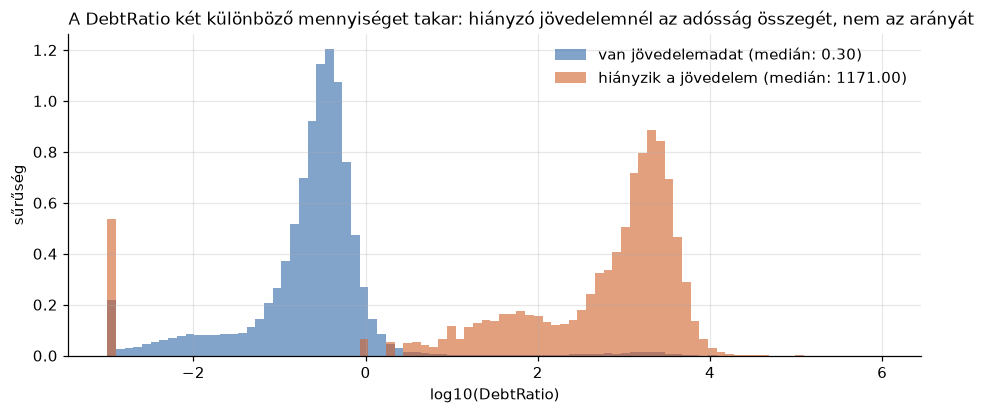

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.linspace(-3, 6, 90)
for miss, lab, col in [(False, "van jövedelemadat", BLUE), (True, "hiányzik a jövedelem", ORANGE)]:
    v = np.log10(d.debt_ratio[d.income.isna() == miss] + 1e-3)
    ax.hist(v, bins=bins, density=True, alpha=.6, color=col, label=f"{lab} (medián: {d.debt_ratio[d.income.isna() == miss].median():.2f})")
ax.set_xlabel("log10(DebtRatio)"); ax.set_ylabel("sűrűség"); ax.legend(frameon=False)
ax.set_title("A DebtRatio két különböző mennyiséget takar: hiányzó jövedelemnél az adósság összegét, nem az arányát", loc="left", fontsize=11)
save(fig, "eda_debtratio")

**Amit az EDA mutat:**
- A pozitív arány **erősen csökken az életkorral**: a fiatalok kockázata többszöröse az idősekének.
- A **korábbi késések** a legerősebb jel: már egyetlen 30–59 napos késés többszörösére emeli az arányt. A **96/98-as „darabszám”** nyilvánvalóan nem darabszám, hanem valamilyen kód, és ezekben a sorokban kiugróan magas a pozitív arány.
- A **hitelkeret-kihasználtság** monoton jel: 90% fölött meredeken nő a kockázat.
- A meglévő jövedelem szerint a kockázat a legalsó negyedtől (~9,5%) a legfelsőig (~4,5%) monoton csökken.
- **A jövedelem hiánya nem véletlen:** ezekben a sorokban a pozitív arány *alacsonyabb* az átlagnál. A hiányzás tehát információt hordoz (lásd a 4. fejezetet).
- A **DebtRatio** eloszlása kettéválik: hiányzó jövedelemnél a mediánja ezres nagyságrendű, ami arányként értelmetlen. Valószínűleg ilyenkor az adósság összege került ebbe az oszlopba (osztó híján).

## 4. Tisztítás

In [6]:
X = X_train_raw; LATE = ["late30", "late60", "late90"]
print("hiányzó értékek:", X.isna().sum()[lambda s: s > 0].to_dict())
code9x = X.late30 >= 96
print(f"96/98-as kód: {code9x.sum()} sor | mindhárom késés-oszlopban egyszerre: {(X[LATE] >= 96).all(axis=1).sum()} | "
      f"pozitív arány itt: {y_train[code9x].mean():.1%}")
print("az ilyen sorokban a többi oszlop:", X[code9x][["util", "debt_ratio", "open_lines"]].median().round(3).to_dict())
mi = X.income.isna()
print(f"jövedelem hiányzik: {mi.mean():.1%} | pozitív arány: hiányzó {y_train[mi].mean():.2%} vs meglévő {y_train[~mi].mean():.2%}")
print(f"eltartottak hiányzik: {X.dependents.isna().sum()} sor, ebből a jövedelem is hiányzik: {(X.dependents.isna() & mi).sum()}")
print(f"DebtRatio medián: hiányzó jövedelemnél {X.debt_ratio[mi].median():.0f}, meglévőnél {X.debt_ratio[~mi].median():.3f}, "
      f"nulla jövedelemnél {X.debt_ratio[X.income == 0].median():.0f}")
print(f"jövedelem = 0: {(X.income == 0).sum()} sor | életkor < 18: {(X.age < 18).sum()} sor ({X.age[X.age < 18].tolist()})")
print(f"util > 1: {(X.util > 1).mean():.1%} | util > 10: {(X.util > 10).sum()} sor, pozitív arány {y_train[X.util > 10].mean():.1%}")
print(f"teljesen azonos sorok a tanító halmazon belül: {X.duplicated().sum()}")

hiányzó értékek: {'income': 23832, 'dependents': 3183}
96/98-as kód: 224 sor | mindhárom késés-oszlopban egyszerre: 224 | pozitív arány itt: 53.1%
az ilyen sorokban a többi oszlop: {'util': 1.0, 'debt_ratio': 0.0, 'open_lines': 0.0}
jövedelem hiányzik: 19.9% | pozitív arány: hiányzó 5.53% vs meglévő 6.97%
eltartottak hiányzik: 3183 sor, ebből a jövedelem is hiányzik: 3183
DebtRatio medián: hiányzó jövedelemnél 1171, meglévőnél 0.296, nulla jövedelemnél 938
jövedelem = 0: 1303 sor | életkor < 18: 1 sor ([0])
util > 1: 2.2% | util > 10: 190 sor, pozitív arány 6.8%
teljesen azonos sorok a tanító halmazon belül: 444


**Döntések és indokok:**

| probléma | döntés | indok |
|---|---|---|
| **96/98 a késés-oszlopokban** | új jelző (`late_code_9x`), a három késés-oszlop ezekben a sorokban hiányzó érték lesz | Ez nem darabszám (senki nem késik 98-szor két év alatt), hanem kód, és mindig mindhárom oszlopban egyszerre szerepel. Ezekben a sorokban a kihasználtság mediánja pontosan 1, a nyitott hitelek száma 0, tehát valószínűleg egy lezárt vagy behajtásra került ügyfél speciális rekordjáról van szó. A pozitív arány itt kiugró (~53%), tehát a kód **jel**: megtartom jelzőként, de nem hagyom, hogy „98 késés”-ként torzítsa a lineáris modellt. |
| **hiányzó jövedelem (~20%)** | új jelző (`income_missing`), a hiányzó értéket a pipeline-on belül mediánnal pótolom | **Jel vagy szivárgás?** A jövedelem hiánya a kérelem beadásakor már tény, nem az eredményből következik. Ezért **jel, nem szivárgás**. A mechanizmus nem véletlenszerű (MNAR-gyanú): itt alacsonyabb a pozitív arány, ezért a jelzőt megtartom. |
| **hiányzó eltartottak** | mediánpótlás a pipeline-ban | Mindegyik ilyen sorban a jövedelem is hiányzik, ugyanaz a mechanizmus, így az `income_missing` jelző ezt is lefedi. |
| **DebtRatio hiányzó/0 jövedelemnél** | az alapmodellben változatlanul hagyom | Ilyenkor valószínűleg összeg, nem arány. A fák a jelzővel együtt szét tudják választani; a javítást a visszacsatolási körben **hipotézisként** próbálom ki (7. fejezet). |
| **életkor < 18** (1 sor, 0 év) | hiányzó értékre állítom | Adathiba, hitelfelvevő nem lehet 0 éves. |
| **util > 1** | megtartom | 1 fölött a keret túllépése, ami valós és kockázatos. A >10 értékek valószínűleg hibásak, de kevesen vannak, és a pozitív arányuk az átlag közelében van. A fák érzéketlenek a szélsőértékekre, a logisztikus regresszió pedig `log1p`-transzformált értékeket kap. |
| **duplikált sorok** | megtartom | Kevés oszlop mellett két különböző ügyfél is lehet teljesen azonos (pl. sok nulla), és nincs ügyfél-azonosító, amivel ezt el lehetne dönteni. |
| **kódolás** | nincs szükség rá | **Nincs kategorikus változó.** A késések száma és az eltartottak száma sorrendes darabszám, ezért számként hagyom (ez lényegében sorszám-kódolás, one-hotra nincs ok). |

**Szivárgás elleni szabály:** a `clean` függvény soronként dolgozik és semmit nem tanul az adatból, ezért mindkét halmazra alkalmazható. Minden, ami tanul (mediánpótlás, skálázás), a pipeline-on belül, foldonként illesztődik.

In [7]:
def clean(d):
    d = d.copy()
    d["late_code_9x"] = (d.late30 >= 96).astype(int)
    d.loc[d.late_code_9x == 1, LATE] = np.nan          # a 96/98 kód, nem darabszám
    d["income_missing"] = d.income.isna().astype(int)
    d.loc[d.age < 18, "age"] = np.nan                   # adathiba
    return d
X_train, X_test = clean(X_train_raw), clean(X_test_raw)
BASE_COLS = list(X_train.columns); print(BASE_COLS)

['util', 'age', 'late30', 'debt_ratio', 'income', 'open_lines', 'late90', 're_loans', 'late60', 'dependents', 'late_code_9x', 'income_missing']


## 5. Alapmodellek

Két előfeldolgozás, a modellcsaládhoz igazítva:
- **logisztikus regresszió:** mediánpótlás, majd a ferde eloszlású változókon `log1p` (állapotmentes, nem tanul), végül standardizálás. Mivel a lineáris modell érzékeny a skálára és a szélsőértékekre, így a 98-as kódok és a 300 000-es DebtRatio sem húzzák el.
- **döntési fa, random forest:** mediánpótlás (a fák a skálára és a monoton transzformációkra érzéketlenek).
- **XGBoost:** semmi, mert a hiányzó értéket natívan kezeli (megtanulja, merre küldje a hiányzó értékeket).

In [8]:
SKEW = ["util", "debt_ratio", "income", "late30", "late60", "late90", "open_lines", "re_loans", "dependents",
        "late_total", "monthly_debt", "debt_ratio_clean", "income_per_person"]
log1p_pos = FunctionTransformer(lambda a: np.log1p(np.clip(a, 0, None)), feature_names_out="one-to-one")
def prep_lin():
    return ColumnTransformer([
        ("skew", make_pipeline(SimpleImputer(strategy="median"), log1p_pos, StandardScaler()), lambda X: [c for c in X.columns if c in SKEW]),
        ("rest", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), lambda X: [c for c in X.columns if c not in SKEW])])
make_lr = lambda: make_pipeline(prep_lin(), LogisticRegression(max_iter=3000))
make_xgb = lambda **kw: XGBClassifier(**{**dict(n_estimators=400, learning_rate=.05, max_depth=4, subsample=.8, colsample_bytree=.8,
                                               tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=0), **kw})
models = {
    "dummy (arány)":    make_pipeline(SimpleImputer(strategy="median"), DummyClassifier(strategy="prior")),
    "logreg":           make_lr(),
    "döntési fa (m=6)": make_pipeline(SimpleImputer(strategy="median"), DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=0)),
    "random forest":    make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(200, min_samples_leaf=20, n_jobs=-1, random_state=0)),
    "xgboost":          make_xgb(),
}

def oof(model, X, y, cv=cv):
    # out-of-fold jóslatok + foldonkénti PR-AUC, ugyanazokon a foldokon minden modellnek
    p, fold = np.zeros(len(y)), []
    for tr, va in cv.split(X, y):
        p[va] = clone(model).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[va])[:, 1]
        fold.append(average_precision_score(y.iloc[va], p[va]))
    return p, np.array(fold)

def metrics(y, p, t):
    y = np.asarray(y); pred = p >= t
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "kiegy. pontosság": balanced_accuracy_score(y, pred), "pontosság": accuracy_score(y, pred),
            "megjelölt": pred.mean(), "találati arány (precision)": precision_score(y, pred, zero_division=0),
            "lefedés (recall)": recall_score(y, pred)}
top10 = lambda p: np.quantile(p, .90)     # a döntési szabály: a legkockázatosabb 10%
thr = lambda n: np.inf if n.startswith("dummy") else top10(P[n])   # a konstans dummy nem tud rangsorolni: senkit sem jelöl meg

P, FOLD = {}, {}
for name, m in models.items():
    P[name], FOLD[name] = oof(m, X_train, y_train); tick(name)
ladder = pd.DataFrame({n: {"PR-AUC (átlag)": FOLD[n].mean(), "PR-AUC (szórás)": FOLD[n].std(),
                           **{k: v for k, v in metrics(y_train, P[n], thr(n)).items() if k != "PR-AUC"}} for n in models}).T
display(ladder.round(3))

[    4 s] dummy (arány)


[    5 s] logreg


[    8 s] döntési fa (m=6)


[   31 s] random forest


[   43 s] xgboost


,PR-AUC (átlag),PR-AUC (szórás),ROC-AUC,kiegy. pontosság,pontosság,megjelölt,találati arány (precision),lefedés (recall)
dummy (arány),0.067,0.000,0.500,0.500,0.933,0.0,0.000,0.000
logreg,0.360,0.008,0.833,0.725,0.903,0.1,0.348,0.520
döntési fa (m=6),0.353,0.004,0.845,0.731,0.904,0.1,0.355,0.532
random forest,0.395,0.009,0.861,0.739,0.906,0.1,0.365,0.546
xgboost,0.399,0.009,0.864,0.738,0.906,0.1,0.363,0.544


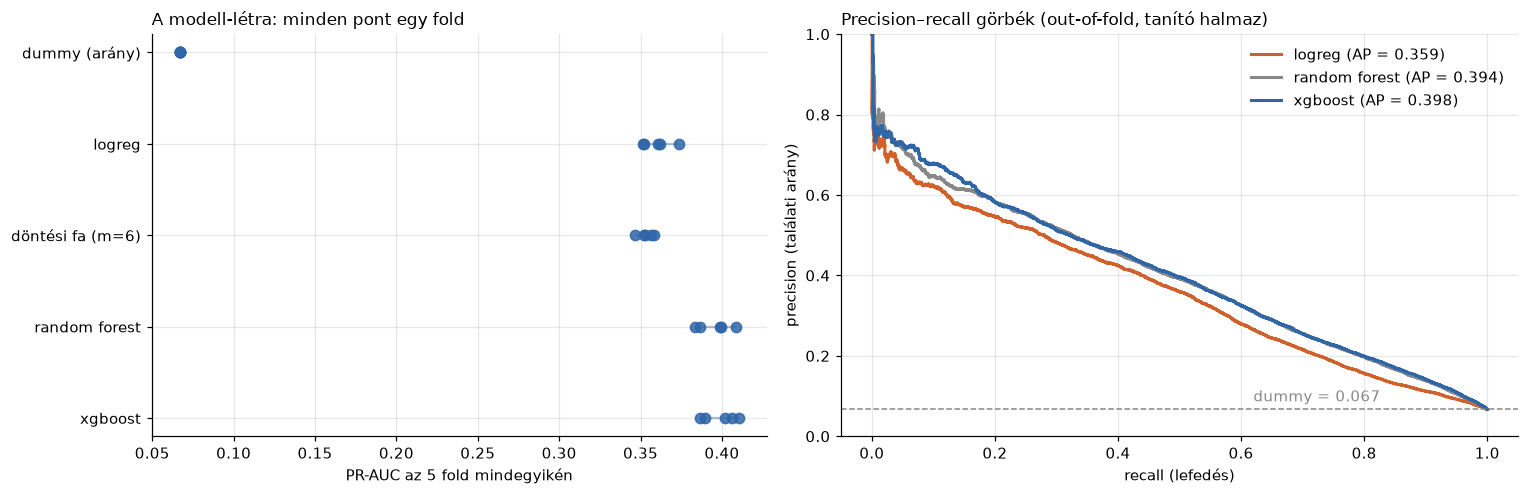

In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
for i, (n, s) in enumerate(FOLD.items()):
    a.scatter(s, [i] * len(s), color=BLUE, s=45, alpha=.85, zorder=3); a.hlines(i, s.min(), s.max(), color=BLUE, alpha=.4)
a.set_yticks(range(len(FOLD))); a.set_yticklabels(FOLD); a.invert_yaxis(); a.set_xlabel("PR-AUC az 5 fold mindegyikén")
a.set_title("A modell-létra: minden pont egy fold", loc="left", fontsize=11)
for n, col in [("logreg", ORANGE), ("random forest", GRAY), ("xgboost", BLUE)]:
    pr, rc, _ = precision_recall_curve(y_train, P[n]); b.plot(rc, pr, color=col, lw=2, label=f"{n} (AP = {average_precision_score(y_train, P[n]):.3f})")
b.axhline(base, ls="--", color=GRAY, lw=1); b.text(.62, base + .02, f"dummy = {base:.3f}", color=GRAY)
b.set_xlabel("recall (lefedés)"); b.set_ylabel("precision (találati arány)"); b.set_ylim(0, 1); b.legend(frameon=False)
b.set_title("Precision–recall görbék (out-of-fold, tanító halmaz)", loc="left", fontsize=11)
plt.tight_layout(); save(fig, "modell_letra")

**A létra eredménye** (PR-AUC, 5 fold átlaga ± szórás):
- dummy 0,067 (ez éppen a pozitívak aránya) → logisztikus regresszió 0,360 → döntési fa 0,353 → random forest 0,395 → XGBoost 0,399 (± 0,009).
- A két ensemble (RF és XGBoost) közti különbség (0,004) **kisebb, mint a foldok közti szórás**, ezért a kettőt nem tudom megbízhatóan szétválasztani. A logisztikus regresszióhoz képest viszont mindkettő egyértelműen jobb: a ~0,04-es különbség a szórás négyszerese, és a foldok pontfelhői sem fedik egymást.
- Az **XGBoostot** viszem tovább: a legjobb pontszámú, gyorsabb, mint a random forest, és natívan kezeli a hiányzó értéket.
- A legkockázatosabb 10%-ban az XGBoost a pozitívak **~54%-át** fogja meg, **~36%-os** találati aránnyal. Véletlen megjelöléssel a találati arány 6,7% lenne, ez tehát ~5,4-szeres javulás (lift).
- A dummy nyers pontossága (93,3%) **magasabb**, mint bármelyik valódi modellé ennél a küszöbnél (~90,6%), pedig egyetlen pozitívat sem talál meg. Ez a 6. fejezet tanulsága előre.

## 6. Mutatók

Az előző táblázat már a választott küszöbnél (legkockázatosabb 10%) mutatja a mutatókat. Itt részletesebben is megnézem a két fő jelöltet. Az alábbi táblázat pedig számokkal mutatja meg, miért félrevezető a nyers pontosság.

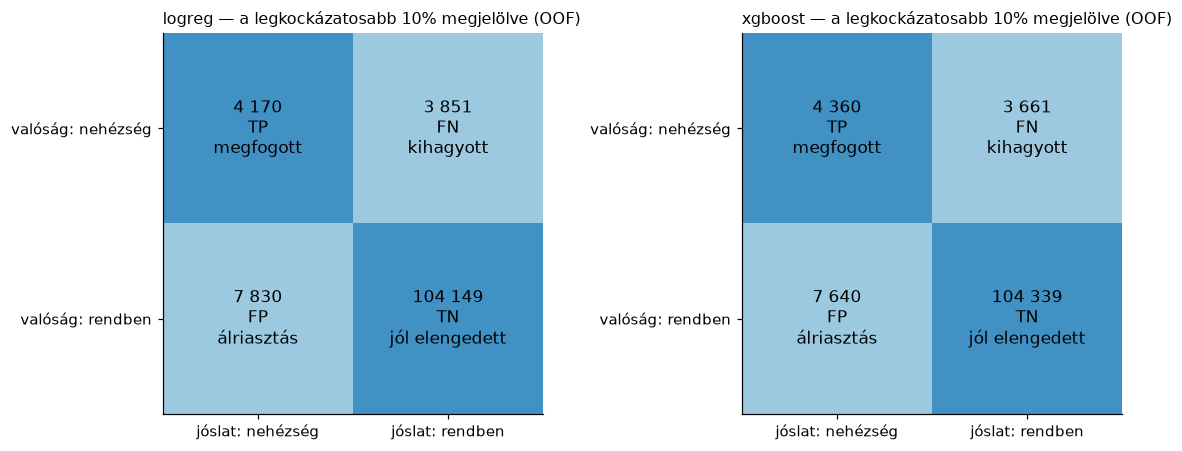

,küszöb,pontosság,kiegy. pontosság,találati arány (precision),lefedés (recall)
megjelölt arány,,,,,
2%,0.519,0.937,0.586,0.602,0.180
5%,0.325,0.931,0.664,0.477,0.357
10%,0.17,0.906,0.738,0.363,0.544
20%,0.083,0.830,0.780,0.241,0.722
30%,0.051,0.744,0.783,0.185,0.828
0% (dummy),-,0.933,0.500,0.000,0.000


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, n in zip(axs, ["logreg", "xgboost"]):
    tn, fp, fn, tp = confusion_matrix(y_train, P[n] >= top10(P[n])).ravel()
    M = np.array([[tp, fn], [fp, tn]]); lab = np.array([["TP\nmegfogott", "FN\nkihagyott"], ["FP\nálriasztás", "TN\njól elengedett"]])
    ax.imshow([[1, 0], [0, 1]], cmap="Blues", vmin=-1.5, vmax=2.5)
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{M[i, j]:,}\n{lab[i, j]}".replace(",", " "), ha="center", va="center", fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["jóslat: nehézség", "jóslat: rendben"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["valóság: nehézség", "valóság: rendben"])
    ax.grid(False); ax.set_title(f"{n} — a legkockázatosabb 10% megjelölve (OOF)", loc="left", fontsize=10.5)
plt.tight_layout(); save(fig, "konfuzios_matrix_oof")

rows = []
for frac in [.02, .05, .10, .20, .30]:
    t = np.quantile(P["xgboost"], 1 - frac); m = metrics(y_train, P["xgboost"], t)
    rows.append({"megjelölt arány": f"{frac:.0%}", "küszöb": round(t, 3), **{k: round(m[k], 3) for k in ["pontosság", "kiegy. pontosság", "találati arány (precision)", "lefedés (recall)"]}})
rows.append({"megjelölt arány": "0% (dummy)", "küszöb": "-", "pontosság": round(1 - base, 3), "kiegy. pontosság": .5, "találati arány (precision)": 0, "lefedés (recall)": 0})
display(pd.DataFrame(rows).set_index("megjelölt arány"))

**A küszöbtáblázat tanulsága:** ahogy több ügyfelet jelölünk meg, a lefedés (recall) és a kiegyensúlyozott pontosság nő, a nyers pontosság viszont *csökken*. A „senkit nem jelölünk” dummy pontossága a legjobb közöttük. Ha a pontosságot optimalizálnánk, a modell gyakorlatilag senkit sem jelölne meg, a bank szempontjából pedig ez a legrosszabb döntés.

## 7. Visszacsatolási kör: hibaelemzés → hipotézis → új jellemzők

A legjobb alapmodell (XGBoost) **out-of-fold** jóslatain nézem meg a hibákat a választott küszöbnél. Az OOF jóslatok a tanító halmazon vannak, és minden jóslatot olyan modell adott, amely azt a sort nem látta.

In [11]:
p = P["xgboost"]; t = top10(p); pred = p >= t
grp = np.select([pred & (y_train == 1), ~pred & (y_train == 1), pred & (y_train == 0), ~pred & (y_train == 0)],
                ["TP (megfogott)", "FN (kihagyott)", "FP (álriasztás)", "TN"], default="")
err = X_train.assign(csoport=grp, p=p, late_any=(X_train[LATE].fillna(0).sum(axis=1) > 0).astype(int))
summary = err.groupby("csoport").agg(db=("p", "size"), p_median=("p", "median"), kor=("age", "median"), util=("util", "median"),
                                     volt_kesese=("late_any", "mean"), jov_hiany=("income_missing", "mean"),
                                     jovedelem=("income", "median"), debt_ratio=("debt_ratio", "median"))
display(summary.round(3))
fn = err[err.csoport == "FN (kihagyott)"]
print(f"A kihagyott pozitívak {1 - fn.late_any.mean():.0%}-ának NINCS korábbi késése; a megfogottaknál ez "
      f"{1 - err[err.csoport == 'TP (megfogott)'].late_any.mean():.0%}.")
print("A 8 legbiztosabban 'rendben'-nek jósolt, mégis bajba került ügyfél:")
display(fn.nsmallest(8, "p")[["age", "util", "late30", "late60", "late90", "debt_ratio", "income", "open_lines", "dependents", "p"]].round(3))

,db,p_median,kor,util,volt_kesese,jov_hiany,jovedelem,debt_ratio
csoport,,,,,,,,
FN (kihagyott),3661,0.068,47.0,0.476,0.314,0.149,5000.0,0.418
FP (álriasztás),7640,0.287,44.0,0.921,0.921,0.160,4200.0,0.426
TN,104339,0.017,53.0,0.112,0.113,0.204,5555.0,0.360
TP (megfogott),4360,0.413,44.0,0.983,0.945,0.177,4034.5,0.432


A kihagyott pozitívak 69%-ának NINCS korábbi késése; a megfogottaknál ez 6%.
A 8 legbiztosabban 'rendben'-nek jósolt, mégis bajba került ügyfél:


,age,util,late30,late60,late90,debt_ratio,income,open_lines,dependents,p
64359,77.0,0.000,0.0,0.0,0.0,0.000,5000.0,3,0.0,0.002
64665,74.0,0.051,0.0,0.0,0.0,1607.000,NaN,5,1.0,0.003
32015,70.0,0.000,0.0,0.0,0.0,1663.000,NaN,4,0.0,0.003
26834,88.0,0.000,0.0,0.0,0.0,0.000,2500.0,4,0.0,0.003
67547,69.0,0.026,0.0,0.0,0.0,0.001,7009.0,3,0.0,0.003
63727,64.0,0.049,0.0,0.0,0.0,2446.000,NaN,4,0.0,0.003
100749,78.0,0.044,0.0,0.0,0.0,32.000,NaN,5,0.0,0.003
112322,66.0,0.027,0.0,0.0,0.0,593.000,NaN,3,0.0,0.004


**Amit a hibák mutatnak:**
- **Kihagyott pozitívak (FN):** **69%-uknak nincs korábbi késése** (a megfogottaknál ez csak 6%), és a hitelkeret-kihasználtságuk mediánja ~48%, szemben a megfogottak ~98%-ával. Náluk tehát a két legerősebb jel hallgat. A legbiztosabban „rendben”-nek jósolt, mégis bajba került ügyfelek idősek, szinte nulla a hitelkeret-kihasználtságuk, nincs késésük, és többüknél a jövedelem is hiányzik: a meglévő oszlopok alapján **megkülönböztethetetlenek a jó ügyfelektől**. Ezt a hibarészt valószínűleg semmilyen jellemző nem javítja ezekből az adatokból.
- **Álriasztások (FP):** szinte ugyanúgy néznek ki, mint a megfogottak (kihasználtság ~92% vs ~98%, késéstörténet 92% vs 95%). Ezek kockázatos ügyfelek, akik végül „megúszták”, tehát nem a modell hibája, hogy megjelölte őket.
- A biztos FN-ek között feltűnően sok a **hiányzó jövedelmű, ezres nagyságrendű DebtRatio-jú** sor: itt a modell egy összeget kap aránynak.

**Hipotézisek.** Ahol nincs késéstörténet, ott a modellnek az eladósodottságból és a jövedelemből kellene dolgoznia, csakhogy ezek az oszlopok zajosak vagy két mennyiséget kevernek:

1. **H1, `late_total`:** a háromféle késés összege. Egyetlen „mennyit késett összesen” szám talán stabilabb jel, mint három ritka oszlop külön.
2. **H2, `monthly_debt` + `debt_ratio_clean`:** a DebtRatio két mennyiséget kever (arányt, illetve hiányzó/0 jövedelemnél összeget). Szétválasztom: `debt_ratio_clean` = az arány csak ott, ahol van jövedelem; `monthly_debt` = havi adósság *összege* (arány × jövedelem, illetve ahol nincs jövedelem, ott maga a DebtRatio). **Két oszlopból számol**, ahogy a feladat tippje javasolja.
3. **H3, `income_per_person`:** jövedelem / (eltartottak + 1). Ugyanaz a jövedelem egy háztartásban szűkösebb, ha több embert tart el. Ez is két oszlopból számol.

A jellemzők soronként, tanulás nélkül számolódnak (nincs szivárgás). Az összehasonlítás **ugyanazokon az 5×2 foldon** történik, páros különbségként (új − alap) ± a különbségek szórása.
**Előre rögzített döntési szabály:** egy jellemzőcsoportot csak akkor tartok meg, ha az átlagos páros javulás **nagyobb, mint a különbségek szórása**.

In [12]:
def add_features(d):
    d = d.copy(); has_inc = d.income > 0
    d["late_total"] = d[LATE].sum(axis=1, min_count=1)
    d["debt_ratio_clean"] = d.debt_ratio.where(has_inc)
    d["monthly_debt"] = np.where(has_inc, d.debt_ratio * d.income, d.debt_ratio)   # jövedelem nélkül a DebtRatio maga az összeg
    d["income_per_person"] = d.income / (d.dependents.fillna(0) + 1)
    return d
Xf_train = add_features(X_train)
FE = {"alap": [], "H1: + late_total": ["late_total"], "H2: + monthly_debt, debt_ratio_clean": ["monthly_debt", "debt_ratio_clean"],
      "H3: + income_per_person": ["income_per_person"], "mind (H1+H2+H3)": ["late_total", "monthly_debt", "debt_ratio_clean", "income_per_person"]}
S = {}
for mname, mk in [("logreg", make_lr), ("xgboost", make_xgb)]:
    for v, cols in FE.items():
        S[(mname, v)] = cross_val_score(mk(), Xf_train[BASE_COLS + cols], y_train, cv=rcv, scoring="average_precision")
    tick(f"jellemzők kiértékelve: {mname}")
rows = []
for (mname, v), s in S.items():
    dl = s - S[(mname, "alap")]
    rows.append({"modell": mname, "változat": v, "PR-AUC": s.mean(), "páros különbség": dl.mean(), "különbség szórása": dl.std(),
                 "javult foldok": f"{(dl > 0).sum()}/{len(dl)}", "megtartom?": bool(v != "alap" and dl.mean() > dl.std())})
fe_tab = pd.DataFrame(rows); display(fe_tab.round(4))

def pick(mname):
    q = fe_tab[(fe_tab.modell == mname) & fe_tab["megtartom?"]]
    return FE[q.sort_values("páros különbség").változat.iloc[-1]] if len(q) else []
FE_LR, FE_XGB = pick("logreg"), pick("xgboost")
print("megtartott új jellemzők -> logreg:", FE_LR or "egyik sem", "| xgboost:", FE_XGB or "egyik sem")

[   62 s] jellemzők kiértékelve: logreg


[  182 s] jellemzők kiértékelve: xgboost


,modell,változat,PR-AUC,páros különbség,különbség szórása,javult foldok,megtartom?
0,logreg,alap,0.3601,0.0000,0.0000,0/10,False
1,logreg,H1: + late_total,0.3575,-0.0026,0.0029,2/10,False
2,logreg,"H2: + monthly_debt, debt_ratio_clean",0.3609,0.0008,0.0004,10/10,True
3,logreg,H3: + income_per_person,0.3601,-0.0000,0.0001,6/10,False
4,logreg,mind (H1+H2+H3),0.3587,-0.0015,0.0030,2/10,False
5,xgboost,alap,0.3995,0.0000,0.0000,0/10,False
6,xgboost,H1: + late_total,0.4005,0.0010,0.0018,7/10,False
7,xgboost,"H2: + monthly_debt, debt_ratio_clean",0.3992,-0.0003,0.0013,5/10,False
8,xgboost,H3: + income_per_person,0.4002,0.0007,0.0020,8/10,False
9,xgboost,mind (H1+H2+H3),0.4017,0.0021,0.0029,7/10,False


megtartott új jellemzők -> logreg: ['monthly_debt', 'debt_ratio_clean'] | xgboost: egyik sem


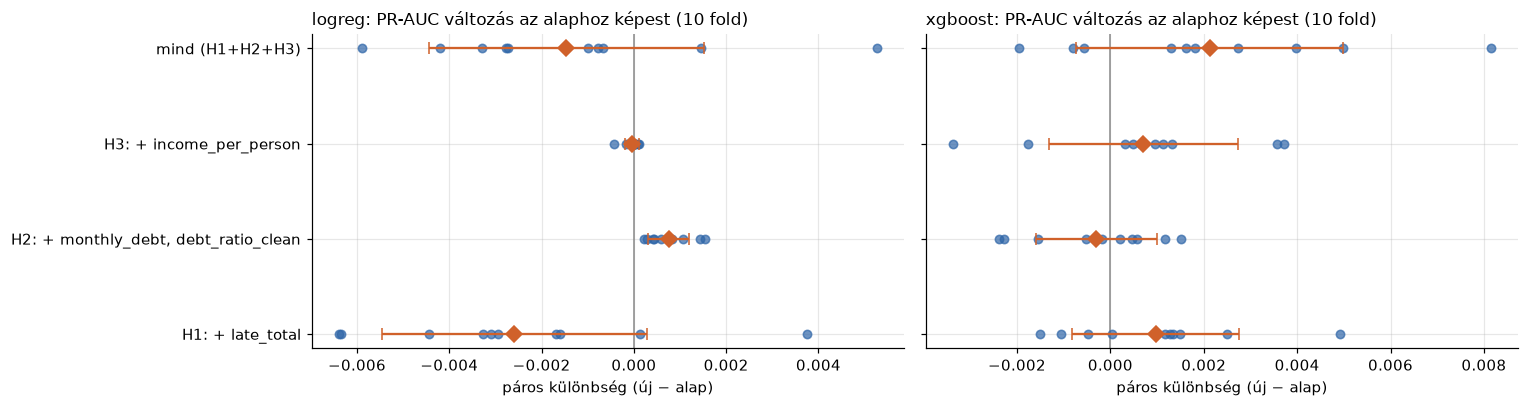

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
vs = [v for v in FE if v != "alap"]
for ax, mname in zip(axs, ["logreg", "xgboost"]):
    for i, v in enumerate(vs):
        dl = S[(mname, v)] - S[(mname, "alap")]
        ax.scatter(dl, [i] * len(dl), color=BLUE, alpha=.7, s=30, zorder=3)
        ax.errorbar(dl.mean(), i, xerr=dl.std(), fmt="D", color=ORANGE, ms=7, capsize=4, zorder=4)
    ax.axvline(0, color=GRAY, lw=1); ax.set_yticks(range(len(vs))); ax.set_yticklabels(vs); ax.invert_yaxis()
    ax.set_title(f"{mname}: PR-AUC változás az alaphoz képest (10 fold)", loc="left", fontsize=11); ax.set_xlabel("páros különbség (új − alap)")
plt.tight_layout(); save(fig, "uj_jellemzok")

**Eredmény (őszintén):**
- **XGBoost: egyik hipotézis sem lépte át az előre rögzített küszöböt.** A legnagyobb javulást a „mind” változat hozta (+0,0021 ± 0,0029, 7/10 foldon jobb), de ez kisebb a szórásnál, tehát nem különböztethető meg a zajtól. A H2, amire a hibaelemzés alapján a legtöbbet építettem, az XGBoostnak semmit sem hozott (−0,0003). Utólagos magyarázat: a fa az `income_missing` jelzővel és a `debt_ratio` vágásaival a két mennyiséget magától is szét tudja választani, a szorzatot pedig lépcsőkkel közelíti. Ez egybevág az órai előzetes méréssel (a feature engineering a fának nem segít).
  **A házi kérdésére a válaszom tehát: nem találtam olyan jellemzőt, ami az XGBoostnak mérhetően segít.** A három két oszlopból számolt jellemző közül egyik sem segített.
- **Logisztikus regresszió:** a H2 kicsi, de nagyon következetes javulást hozott (+0,0008 ± 0,0004, mind a 10 foldon jobb). A szétválasztás itt valóban segít, mert a lineáris modell magától nem tud interakciót tanulni. A javulás nagysága viszont gyakorlatilag jelentéktelen (0,360 → 0,361). A H1 **rontott** (−0,0026): a három késés-oszlop külön súlya több információt hordoz, mint az összegük, mert egy 90+ napos késés többet nyom a latban, mint egy 30 napos.
- A végső XGBoost ezért az **eredeti jellemzőkkel** megy tovább.

## 8. Hangolás

A legjobb modellcsaládot (XGBoost, a 7. fejezetben megtartott jellemzőkkel) véletlen kereséssel hangolom, egy külön 3-foldos CV-n. Utána a hangolt és az alap beállítást **új foldokon** (5×2, más seeddel) hasonlítom össze, olyan vágásokon, amelyeken a keresés nem választott. Csak akkor tartom meg a hangoltat, ha a páros javulás nagyobb a szórásánál. Ha nem, marad az egyszerűbb alap.

In [14]:
Xtr_x = Xf_train[BASE_COLS + FE_XGB]
space = {"n_estimators": randint(200, 900), "learning_rate": loguniform(.01, .15), "max_depth": randint(2, 7),
         "min_child_weight": randint(1, 60), "subsample": uniform(.6, .4), "colsample_bytree": uniform(.5, .5), "reg_lambda": loguniform(.1, 30)}
search = RandomizedSearchCV(make_xgb(n_jobs=1), space, n_iter=25, scoring="average_precision",
                            cv=StratifiedKFold(3, shuffle=True, random_state=1), random_state=0, n_jobs=-1).fit(Xtr_x, y_train)
tick("keresés kész")
print("legjobb CV PR-AUC a keresésben:", round(search.best_score_, 4))
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in search.best_params_.items()})

fresh = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=7)
s_def = cross_val_score(make_xgb(), Xtr_x, y_train, cv=fresh, scoring="average_precision")
s_tun = cross_val_score(make_xgb(**search.best_params_), Xtr_x, y_train, cv=fresh, scoring="average_precision")
dl = s_tun - s_def; USE_TUNED = bool(dl.mean() > dl.std())
print(f"új foldokon: alap {s_def.mean():.4f} | hangolt {s_tun.mean():.4f} | páros különbség {dl.mean():+.4f} ± {dl.std():.4f} "
      f"(javult {(dl > 0).sum()}/{len(dl)} foldon) -> {'a hangoltat' if USE_TUNED else 'az alapot'} tartom meg")

[  343 s] keresés kész
legjobb CV PR-AUC a keresésben: 0.398
{'colsample_bytree': np.float64(0.605), 'learning_rate': np.float64(0.014), 'max_depth': 5, 'min_child_weight': 54, 'n_estimators': 833, 'reg_lambda': np.float64(0.125), 'subsample': np.float64(0.854)}


új foldokon: alap 0.3982 | hangolt 0.4002 | páros különbség +0.0021 ± 0.0021 (javult 8/10 foldon) -> az alapot tartom meg


**Eredmény:** a keresés legjobb beállítása lassabban tanul, több fát és erősebb regularizálást használ (`min_child_weight` ≈ 54). Az új foldokon **+0,0021 ± 0,0021**-et javított (8/10 foldon jobb). Ez határeset: a javulás nem *nagyobb* a szórásnál, tehát a szabály szerint **az egyszerűbb alapbeállítást tartom meg**. Ennyi adatnál az alap XGBoost már közel jár ahhoz, amit ezekből az oszlopokból ki lehet hozni. A ~0,5%-os hangolási nyereség sokkal kisebb, mint a teszt PR-AUC bizonytalansága (±0,024, lásd lent), így a gyakorlatban nem számítana.

## 9. A teszthalmaz, egyszer

Most nyitom fel először a teszthalmazt. A végső modellt és a küszöböt **kizárólag a tanító halmazon** választottam:
- **modell:** az XGBoost (a létrán messze a legjobb volt) a 7–8. fejezet döntései szerint;
- **küszöb:** a végső modell tanító halmazon számolt OOF-pontszámainak 90. percentilise, rögzített számként;
- **összehasonlítás:** az alapmodell (logisztikus regresszió, eredeti jellemzők) és a dummy.

A bizonytalanságot **bootstrap konfidenciaintervallummal** adom meg: a teszthalmazból 2000-szer húzok visszatevéssel ugyanakkora mintát, mindegyiken kiszámolom a PR-AUC-t, és a 2,5. és 97,5. percentilis adja a 95%-os intervallumot. A két modell különbségét **páros** bootstrappal becsülöm (mindkét modell ugyanazon a mintán), ami szűkebb és tisztességesebb, mint két külön intervallumot összevetni.

In [15]:
final = make_xgb(**search.best_params_) if USE_TUNED else make_xgb()
Xte_x = add_features(X_test)[BASE_COLS + FE_XGB]
p_oof_final, _ = oof(final, Xtr_x, y_train)
t_final = top10(p_oof_final); print(f"küszöb a tanító OOF-ból: {t_final:.4f}")

final.fit(Xtr_x, y_train); p_te = final.predict_proba(Xte_x)[:, 1]
lr_base = make_lr().fit(X_train, y_train); p_te_lr = lr_base.predict_proba(X_test)[:, 1]
t_lr = top10(P["logreg"])
res = pd.DataFrame({"dummy": {"PR-AUC": y_test.mean()}, "logreg (alap)": metrics(y_test, p_te_lr, t_lr),
                    "végső XGBoost": metrics(y_test, p_te, t_final)}).T
display(res.round(3))

rng = np.random.default_rng(0); yt = y_test.values; n = len(yt)
B = np.array([(average_precision_score(yt[i], p_te[i]), average_precision_score(yt[i], p_te_lr[i]))
              for i in (rng.integers(0, n, n) for _ in range(2000))])
ci = lambda v: np.percentile(v, [2.5, 97.5])
print(f"PR-AUC végső XGBoost: {average_precision_score(yt, p_te):.3f}  95% CI [{ci(B[:, 0])[0]:.3f}, {ci(B[:, 0])[1]:.3f}]")
print(f"PR-AUC logreg (alap): {average_precision_score(yt, p_te_lr):.3f}  95% CI [{ci(B[:, 1])[0]:.3f}, {ci(B[:, 1])[1]:.3f}]")
dd = B[:, 0] - B[:, 1]
print(f"különbség (XGB − logreg): {average_precision_score(yt, p_te) - average_precision_score(yt, p_te_lr):+.3f}  "
      f"95% CI [{ci(dd)[0]:+.3f}, {ci(dd)[1]:+.3f}]  | a bootstrap minták {(dd > 0).mean():.1%}-ában jobb az XGBoost")
print(f"CV-becslés (OOF) a végső modellre: {average_precision_score(y_train, p_oof_final):.3f}  -> teszt: {average_precision_score(yt, p_te):.3f}")

küszöb a tanító OOF-ból: 0.1700


,PR-AUC,ROC-AUC,kiegy. pontosság,pontosság,megjelölt,találati arány (precision),lefedés (recall)
dummy,0.067,NaN,NaN,NaN,NaN,NaN,NaN
logreg (alap),0.372,0.838,0.729,0.903,0.101,0.350,0.529
végső XGBoost,0.408,0.872,0.747,0.908,0.100,0.375,0.562


PR-AUC végső XGBoost: 0.408  95% CI [0.384, 0.432]
PR-AUC logreg (alap): 0.372  95% CI [0.348, 0.395]
különbség (XGB − logreg): +0.036  95% CI [+0.026, +0.048]  | a bootstrap minták 100.0%-ában jobb az XGBoost
CV-becslés (OOF) a végső modellre: 0.398  -> teszt: 0.408


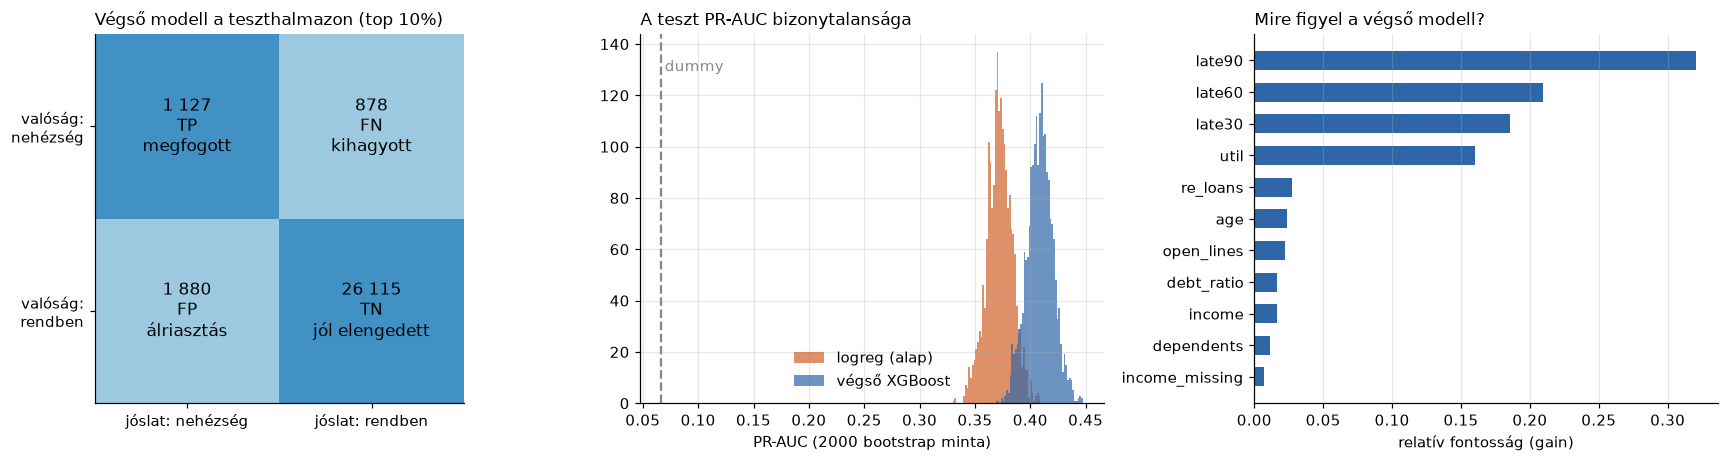

[  494 s] kész


In [16]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
tn, fp, fn_, tp = confusion_matrix(y_test, p_te >= t_final).ravel()
M = np.array([[tp, fn_], [fp, tn]]); lab = np.array([["TP\nmegfogott", "FN\nkihagyott"], ["FP\nálriasztás", "TN\njól elengedett"]])
axs[0].imshow([[1, 0], [0, 1]], cmap="Blues", vmin=-1.5, vmax=2.5)
for i in range(2):
    for j in range(2): axs[0].text(j, i, f"{M[i, j]:,}\n{lab[i, j]}".replace(",", " "), ha="center", va="center", fontsize=11)
axs[0].set_xticks([0, 1]); axs[0].set_xticklabels(["jóslat: nehézség", "jóslat: rendben"]); axs[0].set_yticks([0, 1])
axs[0].set_yticklabels(["valóság:\nnehézség", "valóság:\nrendben"]); axs[0].grid(False)
axs[0].set_title("Végső modell a teszthalmazon (top 10%)", loc="left", fontsize=11)
axs[1].hist(B[:, 1], bins=50, color=ORANGE, alpha=.7, label="logreg (alap)"); axs[1].hist(B[:, 0], bins=50, color=BLUE, alpha=.7, label="végső XGBoost")
axs[1].axvline(y_test.mean(), color=GRAY, ls="--"); axs[1].text(y_test.mean() + .003, axs[1].get_ylim()[1] * .9, "dummy", color=GRAY)
axs[1].set_xlabel("PR-AUC (2000 bootstrap minta)"); axs[1].legend(frameon=False); axs[1].set_title("A teszt PR-AUC bizonytalansága", loc="left", fontsize=11)
imp = pd.Series(final.get_booster().get_score(importance_type="gain")).sort_values()
axs[2].barh(imp.index, imp.values / imp.sum(), color=BLUE, height=.6); axs[2].set_xlabel("relatív fontosság (gain)"); axs[2].grid(axis="y", visible=False)
axs[2].set_title("Mire figyel a végső modell?", loc="left", fontsize=11)
plt.tight_layout(); save(fig, "teszt_eredmeny"); tick("kész")

**Eredmény a teszthalmazon:**
- **PR-AUC 0,408 [95% CI: 0,384–0,432]**. A CV-becslés 0,398 volt; a teszt a konfidenciaintervallumon belül esik, ami arra utal, hogy nincs túlillesztés vagy szivárgás.
- **Alapmodell (logreg): 0,372 [0,348–0,395]**. A páros különbség **+0,036 [+0,026; +0,048]**: az intervallum nem tartalmazza a nullát, tehát az XGBoost valóban jobb. A dummyhoz (0,067) képest ~6×.
- **A döntési szabály a gyakorlatban:** a tanító halmazból rögzített küszöb a teszten is pontosan a kérelmek 10%-át jelöli meg. Ezzel a később bajba kerülők **56%-át** fogja meg (1 127 / 2 005), **37,5%-os** találati aránnyal: minden megfogott ügyfélre ~1,7 álriasztás jut. Ha a bank a kérelmek tizedét nézi át, a problémás ügyfelek több mint felét elkapja.
- **A modell figyelme:** a három késés-oszlop és a hitelkeret-kihasználtság adja a fontosság közel 90%-át. Az életkor, a jövedelem és a DebtRatio jóval kevésbé számít, mint amit az EDA alapján várnánk, mert a hatásuk nagy része a késéstörténeten keresztül már megjelenik.

## 10. Korlátok

1. Az adat egy ismeretlen amerikai bank 2011 körüli mintája, időbélyeg nélkül. Ezért nem tudtam a múltból a jövőre validálni, holott egy éles modellnél ez kötelező lenne: a gazdasági ciklus (például a 2008-as válság utóhatása) eltolhatja mind a pozitív arányt, mind a változók hatását.
2. A hibák nagy része az adatból nem látszik: a kihagyott pozitívak 69%-ának nincs késéstörténete, és alacsony kockázatúnak tűnnek. Ezen sem több hangolás, sem az itt kipróbált jellemzők nem segítettek, csak új adatforrás (például foglalkoztatás, tranzakciós adatok) segíthetne.
3. A tévedések költségarányát (FN : FP) és a 10%-os átvilágítási kapacitást feltételeztem, nem mértem. A valószínűségeket sem kalibráltam, ezért a modell rangsorolásra alkalmas, de a kimenetét nem szabad nemfizetési valószínűségként olvasni.